In [1]:
import pandas as pd

import Bio
from Bio import Align
from Bio import SeqIO
from Bio.Align.substitution_matrices import Array


import matplotlib.pyplot as plt

import math
import numpy as np

In [ ]:
# result from 'ori_hit_collector.py' script

df = pd.read_csv("../data/processed/rep_ori_hits.csv")

df

,matrix_class,ori_1,score_1,position_1,ori_2,score_2,position_2,ori_3,score_3,position_3,genome_length
0,repensiviricetes,TAATCCGAC,130.2,1466,AGATATTAC,130.0,1324,AAATTTAAC,129.4,690,2750
1,repensiviricetes,TACTGGTAC,128.5,563,CAGTTCTAC,128.2,1941,AGATTCTAC,127.4,468,2762
2,repensiviricetes,TGATGTTAC,131.0,412,CGATATTAC,130.1,448,CAAGGTTAC,128.8,721,2604
3,repensiviricetes,TAATATTAC,139.3,2722,CAGTATTAC,130.8,646,TAATGCCAC,130.5,2012,2882
4,repensiviricetes,TACTGCTAC,130.5,794,TAACCATAC,129.1,962,CAGTCTTAC,129.0,525,2723
...,...,...,...,...,...,...,...,...,...,...,...
279,arfiviricetes,TAGTATTAC,138.5,0,AGGTATTAC,132.8,992,TTCTATTAC,132.5,1599,2855
280,arfiviricetes,TAGTGTTAC,135.9,0,AACTCTTAC,133.5,457,AATTGCTAC,132.9,1382,2595
281,arfiviricetes,GAGTAGTAC,132.3,1690,GAATAGTAC,130.7,1815,AAATTGTAC,130.1,174,2419
282,arfiviricetes,TAGTATTAC,138.5,0,AAGTGGTAC,131.2,176,ACGTACTAC,131.0,349,1939


In [28]:
rep_df = df.loc[df['matrix_class'] == 'repensiviricetes']

arf_df = df.loc[df['matrix_class'] == 'arfiviricetes']

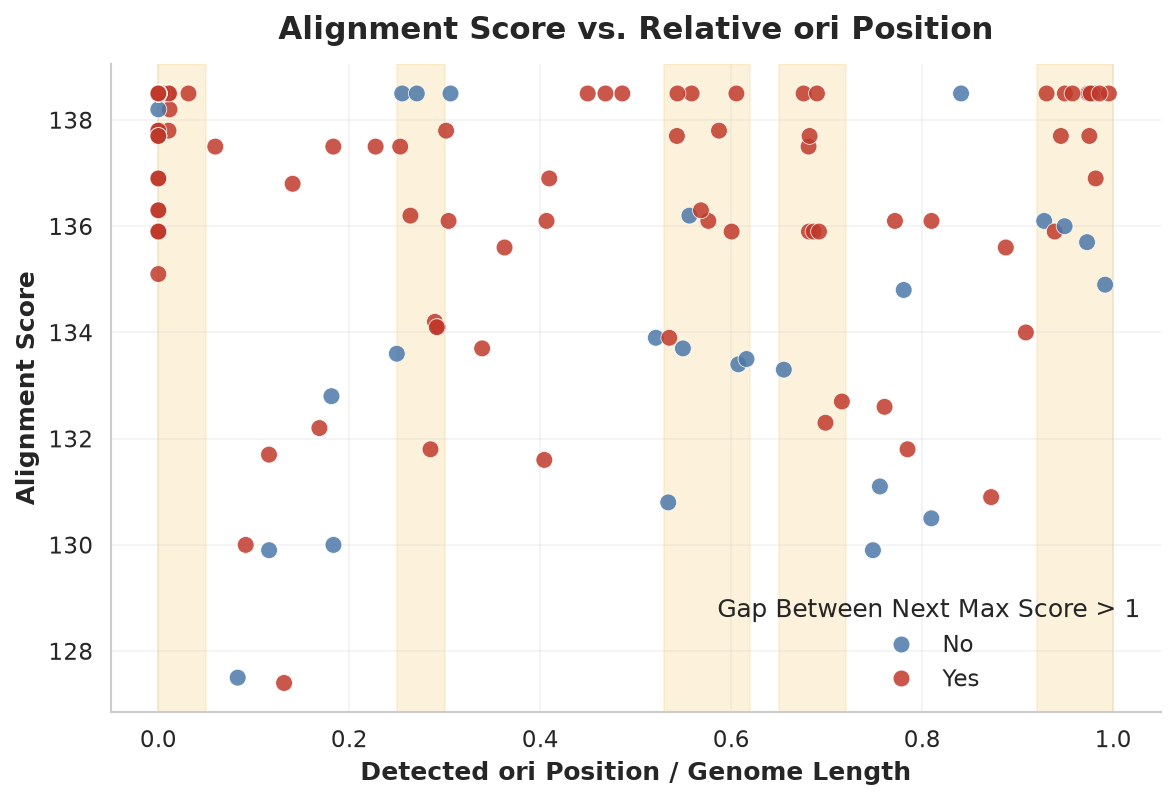

In [42]:
import seaborn as sns
import matplotlib.pyplot as plt

threshold = 1

plot_data = arf_df.copy()
plot_data["score_difference"] = plot_data["score_1"] - plot_data["score_2"]
plot_data["Highlighted"] = plot_data["score_difference"] > threshold
plot_data["relative_position_1"] = (
    plot_data["position_1"] / plot_data["genome_length"]
)

sns.set_theme(
    style="whitegrid",
    context="paper",
    font_scale=1.25,
    rc={
        "axes.titleweight": "bold",
        "axes.labelweight": "bold",
        "grid.alpha": 0.25,
    },
)

fig, ax = plt.subplots(figsize=(8, 5.5), dpi=150)
plot_data["relative_position_1"] = (
    plot_data["position_1"] / plot_data["genome_length"]
)

sns.scatterplot(
    data=plot_data,
    x="relative_position_1",
    y="score_1",
    hue="Highlighted",
    hue_order=[False, True],
    palette={False: "#4C78A8", True: "#C0392B"},
    s=65,
    alpha=0.85,
    edgecolor="white",
    linewidth=0.4,
    ax=ax,
)

x_ranges = [(0.00, 0.05), (0.25, 0.30), (0.53, 0.62), (0.65, 0.72), (0.92, 1)]  # Replace with your two ranges

for start, end in x_ranges:
    ax.axvspan(start, end, color="#F2C14E", alpha=0.20, zorder=0)

ax.set_title("Alignment Score vs. Relative ori Position", pad=12, fontsize=15)
ax.set_xlabel("Detected ori Position / Genome Length")
ax.set_ylabel("Alignment Score")

handles, _ = ax.get_legend_handles_labels()
ax.legend(
    handles=handles,
    labels=["No", "Yes"],
    title=f"Gap Between Next Max Score > {threshold}",
    frameon=False,
)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

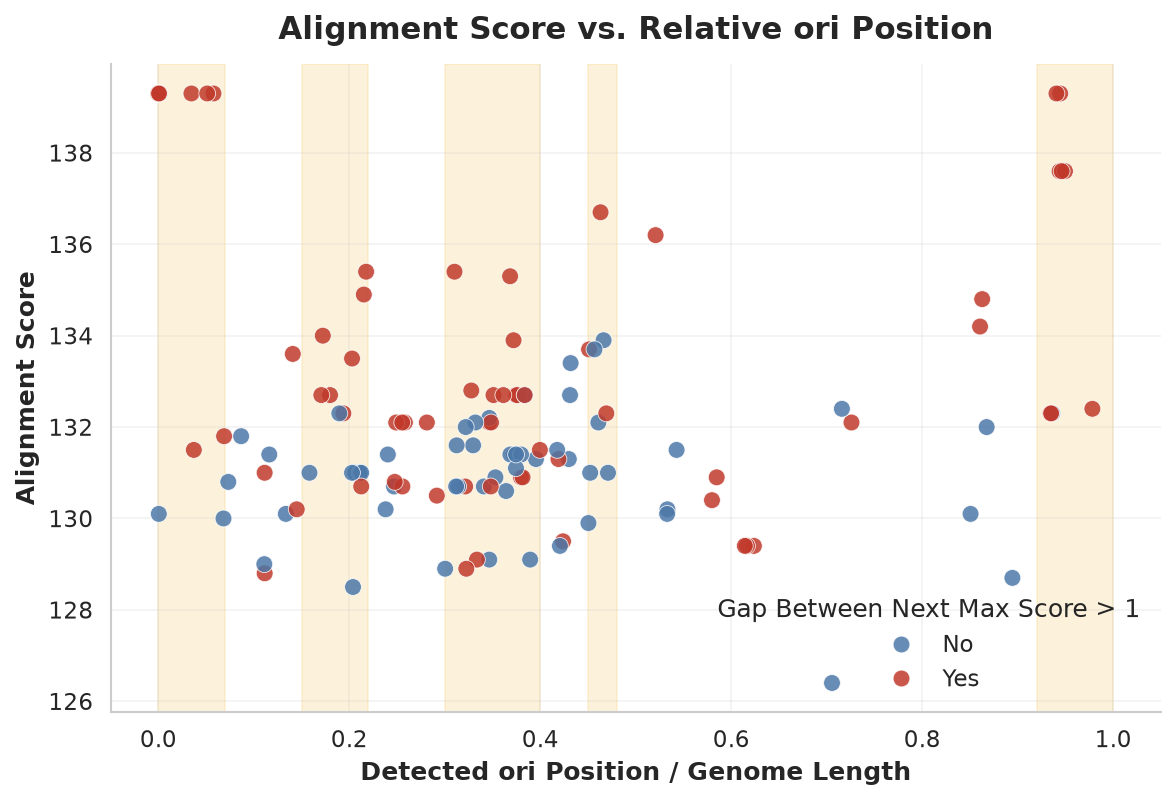

In [50]:
import seaborn as sns
import matplotlib.pyplot as plt

threshold = 1

plot_data = rep_df.copy()
plot_data["score_difference"] = plot_data["score_1"] - plot_data["score_2"]
plot_data["Highlighted"] = plot_data["score_difference"] > threshold
plot_data["relative_position_1"] = (
    plot_data["position_1"] / plot_data["genome_length"]
)

sns.set_theme(
    style="whitegrid",
    context="paper",
    font_scale=1.25,
    rc={
        "axes.titleweight": "bold",
        "axes.labelweight": "bold",
        "grid.alpha": 0.25,
    },
)

fig, ax = plt.subplots(figsize=(8, 5.5), dpi=150)
plot_data["relative_position_1"] = (
    plot_data["position_1"] / plot_data["genome_length"]
)

sns.scatterplot(
    data=plot_data,
    x="relative_position_1",
    y="score_1",
    hue="Highlighted",
    hue_order=[False, True],
    palette={False: "#4C78A8", True: "#C0392B"},
    s=65,
    alpha=0.85,
    edgecolor="white",
    linewidth=0.4,
    ax=ax,
)

x_ranges = [(0.00, 0.07), (0.15, 0.22), (0.30, 0.40), (0.45, 0.48), (0.92, 1)]  # Replace with your two ranges

for start, end in x_ranges:
    ax.axvspan(start, end, color="#F2C14E", alpha=0.20, zorder=0)

ax.set_title("Alignment Score vs. Relative ori Position", pad=12, fontsize=15)
ax.set_xlabel("Detected ori Position / Genome Length")
ax.set_ylabel("Alignment Score")

handles, _ = ax.get_legend_handles_labels()
ax.legend(
    handles=handles,
    labels=["No", "Yes"],
    title=f"Gap Between Next Max Score > {threshold}",
    frameon=False,
)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()